# 近壁 CEX 模型：离子速度分布与能量分布

在 **「输入参数」** 中设置多组工况，再选择 **Restart Kernel and Run All / 重启内核并运行全部**。
每组可独立指定 $E_{\mathrm{close}}$、$\lambda_i$ 和 $L/\lambda_i$。

- `MAX_ENERGY_EV` / `MAX_SPEED_M_S` 可设为 `"case_max"`，使每组数据分别止于自身最大值；`None` 使用全体工况最大值，正数指定统一上限。
- `df` 为完整物理计算数据，`summary_df` 为工况汇总。
- 两张图之后生成 `ivdf_plot_df`、`iedf_plot_df` 和合并的 `plot_data_df`：**n 行采样点、各工况横向排列**。
- 图与表使用完全相同的采样数组。运行第 5 节单元格即直接将 HTML 表格写入系统剪贴板，再在 Excel 中粘贴即可。
- 默认使用近似 Ar⁺ 质量，适用单电荷正离子。全部代码均包含在本文件中。

需要 Python 3.10+、NumPy 2.0+、pandas 2.0+、Matplotlib 3.8+ 和 IPython。
如果缺少依赖，取消下一单元格中 `%pip` 行的注释并运行，再重启内核。


In [1]:
# 首次使用且缺少依赖时，取消下面一行的注释，然后运行本单元格。
# %pip install "numpy>=2.0" "pandas>=2.0" "matplotlib>=3.8" ipython

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display


## 1. 输入参数：修改此单元格

| 参数 | 含义 | 输入单位 |
|---|---|---|
| `case` | 工况名称 | 文本 |
| `E_close_kV_cm` | 近壁平均电场大小，正值 | kV/cm |
| `lambda_mm` | CEX 平均自由程，正值 | mm |
| `L_over_lambda` | 本工况的 $L/\lambda_i$，正值 | 无量纲 |
| `MAX_ENERGY_EV` | IEDF 范围选项：`"case_max"` / `None` / 正数 | eV |
| `MAX_SPEED_M_S` | IVDF 范围选项：`"case_max"` / `None` / 正数 | m/s |
| `N_POINTS` | 每条曲线及对应数据列的采样点数 n；也是原始计算每组的采样数 | 整数 ≥ 4 |

`CASES` 中每行是一组工况，可以增删；未填写 `L_over_lambda` 时使用 `DEFAULT_L_OVER_LAMBDA`。
`ION_MASS_U` 是各工况共用的离子质量。

两项范围参数可分别选择：

| 取值 | 输出行为 |
|---|---|
| `"case_max"`（当前默认） | 每组分别从 0 采样到自身的物理最大值；工况 1 为 200 eV、工况 2 为 500 eV 时，分别只输出到 200、500 eV |
| `None` | 使用全体工况的最大值作为共同采样上限；较短分布后方补零 |
| 正数，例如 `500.0` | 所有工况使用指定的共同上限；超出各自物理上限的值为零 |

`"case_max"` 模式中，每组仍有 n 个点，但横坐标网格不同，因此数据按 **每组横坐标列 + 分布值列** 成对输出。
两项可独立使用不同模式。绘图画布需同时容纳所有曲线，但每条曲线及其输出数据止于自己的上限。
范围设置只控制显示和采样，不改变 L、物理截断上限或归一化系数。


In [2]:
CASES = [
    {"case": "A", "E_close_kV_cm": 1.0, "lambda_mm": 2.0, "L_over_lambda": 1.0},
    {"case": "B", "E_close_kV_cm": 1.0, "lambda_mm": 2.0, "L_over_lambda": 3.0},
    {"case": "C", "E_close_kV_cm": 1.0, "lambda_mm": 2.0, "L_over_lambda": 5.0},
    {"case": "D", "E_close_kV_cm": 1.5, "lambda_mm": 1.0, "L_over_lambda": 3.0},
]

DEFAULT_L_OVER_LAMBDA = 3.0
ION_MASS_U = 39.948          # Ar+ 的近似质量，单位 u
N_POINTS = 2001             # 每张图和绘图数据表的采样点数 n

MAX_ENERGY_EV = "case_max"   # 各工况各自的最大能量；None = 全体最大值；正数 = 统一指定上限（eV）
MAX_SPEED_M_S = "case_max"   # 各工况各自的最大速度；None = 全体最大值；正数 = 统一指定上限（m/s）

EXPORT_PNG = False          # True 时只保存两张 PNG；数据使用下方 HTML 复制
OUTPUT_DIRECTORY = "near_wall_iedf_results"

display(pd.DataFrame(CASES))


,case,E_close_kV_cm,lambda_mm,L_over_lambda
0,A,1.0,2.0,1.0
1,B,1.0,2.0,3.0
2,C,1.0,2.0,5.0
3,D,1.5,1.0,3.0


## 2. 公式与计算函数

令 $r=L/\lambda_i$、$L=r\lambda_i$、$A=1-\exp(-r)$。
电场、长度和质量换算为 SI 单位后：

$$
u_m=\sqrt{\frac{2eE_{\mathrm{close}}L}{M}},\qquad
f(u_a)=\frac{2Lu_a}{\lambda_i u_m^2 A}
\exp\!\left(-\frac{Lu_a^2}{\lambda_i u_m^2}\right),
\quad 0\leq u_a\leq u_m.
$$

对于单电荷离子，以 eV 表示能量时，定义能量尺度的数值
$\varepsilon_0=E_{\mathrm{close}}[\mathrm{V/m}]\lambda_i[\mathrm{m}]$，则：

$$
\varepsilon_{\max}=r\varepsilon_0,\qquad
g(\varepsilon)=\frac{\exp(-\varepsilon/\varepsilon_0)}{\varepsilon_0 A},
\quad 0\leq\varepsilon\leq\varepsilon_{\max}.
$$

这里 $f$ 的单位是 $(\mathrm{m/s})^{-1}$，$g$ 的单位是 $\mathrm{eV}^{-1}$；区间外均为零。
两个分布均对 **末次 CEX 位于 $0\leq x_0\leq L$ 的到达离子** 条件归一化。

下面使用与公式等价的数值形式：通过 `expm1` 避免小 $r$ 时的相减误差；直接计算 $g(0)$，避免在零速度处使用 $f/(Mu_a)$。
通常无需修改计算函数。

In [3]:
ELEMENTARY_CHARGE_C = 1.602176634e-19
ATOMIC_MASS_UNIT_KG = 1.66053906660e-27
DEFAULT_ION_MASS_KG = 39.948 * ATOMIC_MASS_UNIT_KG


def _positive(value, field):
    try:
        number = float(value)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{field} must be a finite positive number.") from exc
    if not np.isfinite(number) or number <= 0:
        raise ValueError(f"{field} must be a finite positive number.")
    return number

def _speed_fraction_grid(ratio, n_points):
    """Resolve the populated range even for L/lambda much larger than one."""
    if ratio <= 25:
        return np.linspace(0.0, 1.0, n_points)
    # The core ends at x0/lambda=25, leaving an exponentially small tail.
    core_end = np.sqrt(25.0 / ratio)
    core_points = max(3, min(n_points - 1, int(0.9 * n_points)))
    return np.concatenate([
        np.linspace(0.0, core_end, core_points),
        np.linspace(core_end, 1.0, n_points - core_points + 1)[1:],
    ])

In [4]:
def calculate_distributions(
    cases,
    *,
    ion_mass_kg=DEFAULT_ION_MASS_KG,
    L_over_lambda=3.0,
    n_points=2001,
):
    """Return the full pandas DataFrame for all cases.

    cases: list of dicts, or a DataFrame. Required fields: E_close_kV_cm,
        lambda_mm. Optional fields: case, L_over_lambda. A missing/blank
        L_over_lambda uses the function's default, independently per case.
    ion_mass_kg: common singly charged ion mass; default is approximately Ar+.
    L_over_lambda: default positive truncation ratio; each row can override it.
    n_points: number of paired velocity/energy samples for each case.

    f_per_m_s is an ARRIVAL probability density per (m/s), not a local
    density-weighted velocity distribution. g_per_eV is per eV, not per joule.
    Both are conditional on the last CEX lying within [0, L].
    """
    mass = _positive(ion_mass_kg, "ion_mass_kg")
    default_ratio = _positive(L_over_lambda, "L_over_lambda")
    if isinstance(n_points, (bool, np.bool_)) or not isinstance(n_points, (int, np.integer)) or n_points < 4:
        raise ValueError("n_points must be an integer >= 4 (2001 recommended).")
    if isinstance(cases, pd.DataFrame):
        cases = cases.to_dict("records")
    else:
        cases = list(cases)
    if not cases:
        raise ValueError("Provide at least one case.")

    frames = []
    for case_id, row in enumerate(cases, start=1):
        if not hasattr(row, "get"):
            raise ValueError(f"Case {case_id}: expected a dict-like row.")
        try:
            field_input = _positive(row.get("E_close_kV_cm"), "E_close_kV_cm")
            lambda_input = _positive(row.get("lambda_mm"), "lambda_mm")
            raw_ratio = row.get("L_over_lambda", default_ratio)
            if raw_ratio is None or (isinstance(raw_ratio, str) and not raw_ratio.strip()) or pd.isna(raw_ratio):
                raw_ratio = default_ratio
            ratio = _positive(raw_ratio, "L_over_lambda")
        except ValueError as exc:
            raise ValueError(f"Case {case_id}: {exc}") from exc

        label = row.get("case", f"Case {case_id}")
        if label is None or pd.isna(label) or not str(label).strip():
            label = f"Case {case_id}"
        label = str(label)
        field_si = field_input * 1e5
        lambda_si = lambda_input * 1e-3
        length_si = ratio * lambda_si
        energy_scale = field_si * lambda_si  # Energy NUMERICALLY in eV, z=1.
        energy_max = energy_scale * ratio
        speed_max = np.sqrt(2 * ELEMENTARY_CHARGE_C * energy_max / mass)
        if not all(np.isfinite(v) and v > 0 for v in (field_si, lambda_si, length_si, energy_scale, energy_max, speed_max)):
            raise ValueError(f"Case {case_id}: parameters exceed floating-point range.")

        inside = -np.expm1(-ratio)  # Stable also when ratio is much smaller than 1.
        outside = np.exp(-ratio)
        q = _speed_fraction_grid(ratio, n_points)
        speed = speed_max * q
        energy = energy_max * q**2
        survival = np.exp(-ratio * q**2)

        # This form avoids dividing f by u=0 and is stable for small ratios.
        f_velocity = (2 * (ratio / inside) / speed_max) * q * survival
        g_energy = ((ratio / inside) / energy_max) * survival
        if not np.all(np.isfinite(f_velocity)) or not np.all(np.isfinite(g_energy)):
            raise ValueError(f"Case {case_id}: probability density exceeds floating-point range.")

        frames.append(pd.DataFrame({
            "case_id": case_id,
            "case": label,
            "E_close_kV_cm": field_input,
            "lambda_mm": lambda_input,
            "L_over_lambda": ratio,
            "L_mm": length_si * 1e3,
            "ion_mass_kg": mass,
            "energy_scale_eV": energy_scale,
            "energy_max_eV": energy_max,
            "u_m_m_s": speed_max,
            "inside_fraction": inside,
            "outside_fraction": outside,
            "x0_mm": length_si * 1e3 * q**2,
            "u_a_m_s": speed,
            "f_per_m_s": f_velocity,
            "energy_eV": energy,
            "g_per_eV": g_energy,
        }))

    df = pd.concat(frames, ignore_index=True)
    return df

def summarize(df):
    """One row per case, including numerical integrals of the sampled PDFs."""
    columns = [
        "case_id", "case", "E_close_kV_cm", "lambda_mm", "L_over_lambda",
        "L_mm", "ion_mass_kg", "energy_scale_eV", "energy_max_eV", "u_m_m_s",
        "inside_fraction", "outside_fraction",
    ]
    rows = []
    for _, data in df.groupby("case_id", sort=False):
        row = data.iloc[0][columns].to_dict()
        row["integral_f"] = np.trapezoid(data["f_per_m_s"], data["u_a_m_s"])
        row["integral_g"] = np.trapezoid(data["g_per_eV"], data["energy_eV"])
        rows.append(row)
    return pd.DataFrame(rows)

## 3. 计算与 DataFrame

`df` 按工况纵向拼接；每一行的速度、能量和末次 CEX 位置相互对应：
$\varepsilon[\mathrm{eV}]=Mu_a^2/(2e)$。
默认速度网格均匀，能量网格非均匀；当 $r>25$ 时自动加密主要概率所在的低能量区域。

`summary_df` 给出每组工况的实际 $L$、模型内最大速度/能量、覆盖比例及数值归一化结果。

In [5]:
df = calculate_distributions(
    CASES,
    ion_mass_kg=ION_MASS_U * ATOMIC_MASS_UNIT_KG,
    L_over_lambda=DEFAULT_L_OVER_LAMBDA,
    n_points=N_POINTS,
)
summary_df = summarize(df)

print(f"已计算 {len(summary_df)} 组工况，共 {len(df):,} 个采样点。")
display(summary_df[[
    "case", "E_close_kV_cm", "lambda_mm", "L_over_lambda", "L_mm",
    "energy_max_eV", "u_m_m_s",
]].round(5))

已计算 4 组工况，共 8,004 个采样点。


,case,E_close_kV_cm,lambda_mm,L_over_lambda,L_mm,energy_max_eV,u_m_m_s
0,A,1.0,2.0,1.0,2.0,200.0,31082.29824
1,B,1.0,2.0,3.0,6.0,600.0,53836.11976
2,C,1.0,2.0,5.0,10.0,1000.0,69502.13175
3,D,1.5,1.0,3.0,3.0,450.0,46623.44735


### 区域覆盖比例与归一化检查

`inside_fraction` 为 $1-\exp(-r)$，`outside_fraction` 为 $\exp(-r)$。
这是当前准稳态、固定平均自由程模型中的覆盖比例。
`integral_f` 和 `integral_g` 应接近 1；如果离散积分偏差较大，可增加 `N_POINTS`。
程序保留解析概率密度，不会为使离散积分恰好为 1 而重新缩放曲线。

In [6]:
display(summary_df[[
    "case", "inside_fraction", "outside_fraction", "integral_f", "integral_g",
]].round(9))

normalization_error = float(np.max(np.abs(
    summary_df[["integral_f", "integral_g"]].to_numpy() - 1.0
)))
print(f"归一化积分的最大绝对误差：{normalization_error:.3e}")
if normalization_error > 1e-3:
    print("当前网格的积分误差较大，请增加 N_POINTS 后重新运行。")

归一化积分的最大绝对误差：4.025e-07


,case,inside_fraction,outside_fraction,integral_f,integral_g
0,A,0.632121,0.367879,1.0,1.0
1,B,0.950213,0.049787,1.0,1.0
2,C,0.993262,0.006738,1.0,1.0
3,D,0.950213,0.049787,1.0,1.0


### 完整结果 `df` 的预览

下面仅显示每个工况的前三行；完整数据已保存在变量 `df`。
可使用 `df[df["case_id"] == 1]` 提取第一个工况。

| 数据列 | 含义 / 单位 |
|---|---|
| `x0_mm` | 末次 CEX 距基板的距离，mm |
| `u_a_m_s` | 到达速度，m/s |
| `f_per_m_s` | 速度概率密度，(m/s)⁻¹ |
| `energy_eV` | 与本行速度对应的能量，eV |
| `g_per_eV` | 能量概率密度，eV⁻¹ |

原始输入、实际区域长度、能量尺度和覆盖比例也保留在 `df` 中。

In [7]:
preview_columns = [
    "case_id", "case", "x0_mm", "u_a_m_s", "f_per_m_s", "energy_eV", "g_per_eV",
]
with pd.option_context("display.float_format", lambda value: f"{value:.6g}"):
    display(df.groupby("case_id", sort=False).head(3)[preview_columns])

,case_id,case,x0_mm,u_a_m_s,f_per_m_s,energy_eV,g_per_eV
0,1,A,0,0,0,0,0.00790988
1,1,A,5e-07,15.5411,5.08964e-08,5e-05,0.00790988
2,1,A,2e-06,31.0823,1.01793e-07,0.0002,0.00790988
2001,2,B,0,0,0,0,0.00526198
2002,2,B,1.5e-06,26.9181,5.86444e-08,0.00015,0.00526197
2003,2,B,6e-06,53.8361,1.17288e-07,0.0006,0.00526196
4002,3,C,0,0,0,0,0.00503392
4003,3,C,2.5e-06,34.7511,7.24282e-08,0.00025,0.00503391
4004,3,C,1e-05,69.5021,1.44856e-07,0.001,0.00503389
6003,4,D,0,0,0,0,0.00701597


## 4. 绘图：各工况自身上限或统一范围

`"case_max"` 模式为每组建立自己的 0–自身最大值网格，各保留 `N_POINTS` 个等间隔点，曲线和数据均在自身上限结束，不向全体最大值补零。
例如两个工况的最大能量分别为 200 eV、500 eV，最后一行的能量横坐标即分别为 200、500。

`None` 或正数仍使用共同网格；各工况物理截断以外的概率密度为零。
两张图中同一工况颜色一致。任意范围模式均不重新归一化。

各工况、速度分布和能量分布的网格可以不同；应将每条分布与其对应横坐标列成对使用。
需要同一粒子的速度—能量对应关系时，仍使用前面的 `df`。


In [8]:
def make_plot_data(dataframe, *, n_points=2001, max_energy_eV=None, max_speed_m_s=None):
    """Build wide plot/export tables with common or per-case x grids.

    Each option independently accepts "case_max", None (overall maximum), or
    a positive number (fixed common maximum). Every curve has n_points rows.
    In case_max mode each case has its own x/y column pair and ends exactly at
    its own physical maximum. Table attrs record which columns form a curve.
    """
    if isinstance(n_points, (bool, np.bool_)) or not isinstance(n_points, (int, np.integer)) or n_points < 4:
        raise ValueError("n_points must be an integer >= 4.")
    groups = list(dataframe.groupby("case_id", sort=False))
    if not groups:
        raise ValueError("Provide at least one calculated case.")

    def range_option(value, overall_max, field):
        if isinstance(value, str) and value == "case_max":
            return True, None
        if value is None:
            return False, float(overall_max)
        return False, _positive(value, field)

    energy_per_case, energy_limit = range_option(
        max_energy_eV, dataframe["energy_max_eV"].max(), "MAX_ENERGY_EV")
    speed_per_case, speed_limit = range_option(
        max_speed_m_s, dataframe["u_m_m_s"].max(), "MAX_SPEED_M_S")
    common_speeds = None if speed_per_case else np.linspace(0.0, speed_limit, n_points)
    common_energies = None if energy_per_case else np.linspace(0.0, energy_limit, n_points)
    velocity_data = {} if speed_per_case else {"u_a_m_s": common_speeds}
    energy_data = {} if energy_per_case else {"energy_eV": common_energies}
    velocity_curves, energy_curves = [], []

    for case_id, group in groups:
        row = group.iloc[0]
        ratio = float(row["L_over_lambda"])
        inside = -np.expm1(-ratio)
        speed_max = float(row["u_m_m_s"])
        energy_max = float(row["energy_max_eV"])
        energy_scale = float(row["energy_scale_eV"])
        speeds = np.linspace(0.0, speed_max, n_points) if speed_per_case else common_speeds
        energies = np.linspace(0.0, energy_max, n_points) if energy_per_case else common_energies
        q = speeds / speed_max
        with np.errstate(over="ignore", under="ignore", invalid="ignore"):
            f = (2 * (ratio / inside) / speed_max) * q * np.exp(-ratio * q**2)
            g = np.exp(-energies / energy_scale) / (energy_scale * inside)
        f = np.where(speeds <= speed_max, f, 0.0)
        g = np.where(energies <= energy_max, g, 0.0)
        if not np.all(np.isfinite(f)) or not np.all(np.isfinite(g)):
            raise ValueError(f"Case {case_id}: plot density exceeds floating-point range.")
        tag = (
            f"{case_id}:{row['case']} | E={row['E_close_kV_cm']:g} kV/cm, "
            f"lambda={row['lambda_mm']:g} mm, L/lambda={ratio:g}"
        )
        speed_column = f"u_a_m_s | {case_id}:{row['case']}" if speed_per_case else "u_a_m_s"
        energy_column = f"energy_eV | {case_id}:{row['case']}" if energy_per_case else "energy_eV"
        f_column = f"IVDF {tag} [(m/s)^-1]"
        g_column = f"IEDF {tag} [eV^-1]"
        if speed_per_case:
            velocity_data[speed_column] = speeds
        if energy_per_case:
            energy_data[energy_column] = energies
        velocity_data[f_column] = f
        energy_data[g_column] = g
        velocity_curves.append({"case_id": case_id, "x": speed_column, "y": f_column})
        energy_curves.append({"case_id": case_id, "x": energy_column, "y": g_column})

    ivdf = pd.DataFrame(velocity_data)
    iedf = pd.DataFrame(energy_data)
    ivdf.index = iedf.index = pd.RangeIndex(1, n_points + 1, name="sample")
    ivdf.attrs["curves"] = velocity_curves
    iedf.attrs["curves"] = energy_curves
    return ivdf, iedf


ivdf_plot_df, iedf_plot_df = make_plot_data(
    df,
    n_points=N_POINTS,
    max_energy_eV=MAX_ENERGY_EV,
    max_speed_m_s=MAX_SPEED_M_S,
)
plot_ranges_df = pd.DataFrame([
    {
        "case_id": v["case_id"],
        "case": row["case"],
        "speed_output_max_m_s": ivdf_plot_df[v["x"]].iloc[-1],
        "energy_output_max_eV": iedf_plot_df[e["x"]].iloc[-1],
    }
    for v, e, (_, row) in zip(
        ivdf_plot_df.attrs["curves"], iedf_plot_df.attrs["curves"],
        summary_df.iterrows(),
    )
])
print(f"每条曲线采样点数：{len(ivdf_plot_df):,}；以下为各工况实际输出上限。")
display(plot_ranges_df)


每条曲线采样点数：2,001；以下为各工况实际输出上限。


,case_id,case,speed_output_max_m_s,energy_output_max_eV
0,1,A,31082.298236,200.0
1,2,B,53836.119760,600.0
2,3,C,69502.131752,1000.0
3,4,D,46623.447353,450.0


In [9]:
def plot_distribution(plot_dataframe, distribution, case_summary):
    settings = {
        "velocity": (
            "u_a_m_s", "f_per_m_s", "Ion arrival velocity distribution",
            r"Arrival speed $u_a$ (m/s)", r"$f(u_a)$  [(m/s)$^{-1}$]",
        ),
        "energy": (
            "energy_eV", "g_per_eV", "Ion arrival energy distribution",
            r"Ion energy $\varepsilon$ (eV)", r"$g(\varepsilon)$  [eV$^{-1}$]",
        ),
    }
    if distribution not in settings:
        raise ValueError("distribution must be 'velocity' or 'energy'.")
    x_col, y_col, title, x_label, y_label = settings[distribution]
    groups = list(case_summary.iterrows())
    curves = plot_dataframe.attrs.get("curves", [])
    if len(curves) != len(groups):
        raise ValueError("Plot curve mapping and case metadata do not match.")
    x_limit = max(float(plot_dataframe[curve["x"]].iloc[-1]) for curve in curves)
    palette = plt.get_cmap("tab10" if len(groups) <= 10 else "turbo")
    available = {font.name for font in font_manager.fontManager.ttflist}
    cjk_fonts = [name for name in (
        "Noto Sans CJK SC", "Noto Sans CJK JP", "Microsoft YaHei",
        "SimHei", "PingFang SC", "WenQuanYi Micro Hei",
    ) if name in available]
    with plt.rc_context({
        "font.family": cjk_fonts + ["DejaVu Sans"],
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#253247",
        "axes.edgecolor": "#9aa5b1",
        "grid.color": "#dce2e8",
        "savefig.facecolor": "white",
    }):
        fig, ax = plt.subplots(figsize=(9.6, 6.2), layout="constrained")
        for index, (_, row) in enumerate(groups):
            color = palette(index if len(groups) <= 10 else index / max(1, len(groups) - 1))
            label = (
                f"{row['case']} | E={row['E_close_kV_cm']:g} kV/cm, "
                f"lambda={row['lambda_mm']:g} mm, L/lambda={row['L_over_lambda']:g}"
            )
            curve = curves[index]
            if curve["case_id"] != row["case_id"]:
                raise ValueError("Plot curve order and case metadata do not match.")
            ax.plot(
                plot_dataframe[curve["x"]], plot_dataframe[curve["y"]], color=color, linewidth=2.2,
                linestyle=["-", "--", "-.", ":"][index % 4], label=label,
            )
        ax.set(title=title, xlabel=x_label, ylabel=y_label)
        ax.set_xlim(0.0, x_limit)
        ax.set_ylim(bottom=0)
        ax.grid(True, alpha=0.7, linewidth=0.7)
        ax.set_axisbelow(True)
        ax.ticklabel_format(axis="y", style="sci", scilimits=(-3, 3), useMathText=True)
        ax.legend(
            loc="upper center", bbox_to_anchor=(0.5, -0.16), frameon=False,
            fontsize=8.5, title="Conditional on last CEX within 0 <= x0 <= L",
            title_fontsize=9,
        )
    return fig


### 速度分布 $f(u_a)$

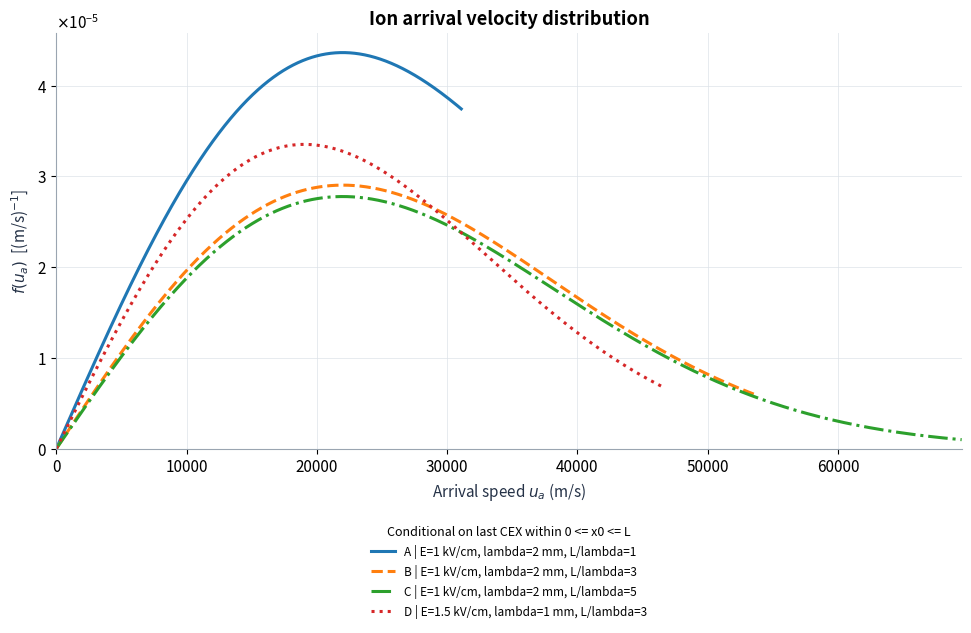

In [10]:
fig_velocity = plot_distribution(ivdf_plot_df, "velocity", summary_df)
display(fig_velocity)
plt.close(fig_velocity)


### 能量分布 $g(\varepsilon)$

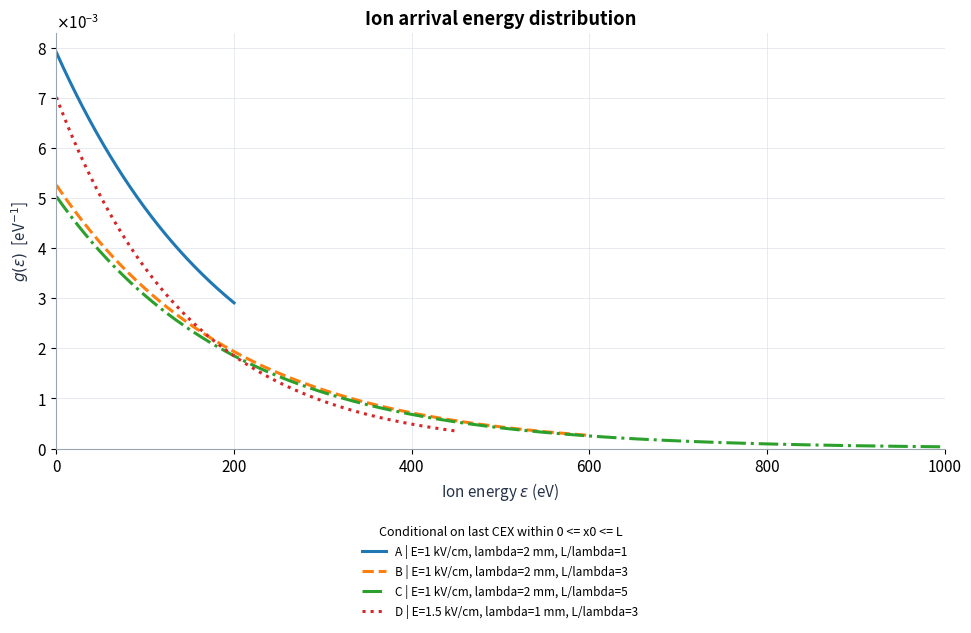

In [11]:
fig_energy = plot_distribution(iedf_plot_df, "energy", summary_df)
display(fig_energy)
plt.close(fig_energy)


## 5. 运行即复制：绘图数据 DataFrame → HTML 系统剪贴板

运行下一单元格，立即将完整 HTML 表格写入系统剪贴板；随后直接在 Excel 中粘贴。**无需点击按钮、手动选择表格或下载文件。**

- `ivdf_plot_df` / `iedf_plot_df`：各 n 行；`"case_max"` 模式按每组的横坐标与分布值成对排列。
- `plot_data_df`：两表横向合并。两项均为 `"case_max"` 时，共 n 行 ×（4 × 工况数）列；数值与绘图数组一致。
- 例如工况 1 最大能量为 200 eV、工况 2 为 500 eV，对应两列能量分别采样 0–200、0–500 eV，各含 n 点。
- 统一范围模式仍使用公共横坐标列；两项均统一时共（2 + 2 × 工况数）列。
- `plot_data_html`：完整 HTML 表格字符串；保留约 15 位有效数字，包含列名，不复制 DataFrame 索引。

各工况可以使用不同横坐标网格；粘贴到 Excel 后，每条分布需使用它自己对应的横坐标列。速度和能量各自均匀，同一行不要求满足同一离子的速度—能量映射。

**运行环境：** Windows 本机 Jupyter / VS Code 不需要额外剪贴板依赖；使用系统 HTML 剪贴板格式，可直接粘贴为 Excel 单元格。
macOS 需 `pyobjc-framework-Cocoa`；Linux 桌面需 `wl-clipboard`（Wayland）或 `xclip`（X11）。
剪贴板属于 **运行 Python 内核的电脑**：如果内核位于远程服务器，此代码不能直接修改浏览器所在电脑的剪贴板；请在客户本机执行。
成功后才输出“已写入”提示；无可用系统剪贴板时明确报错，不会显示虚假的复制成功信息。此单元格不输出 CSV 或 HTML 下载文件。


In [ ]:
def _windows_html_payload(fragment):
    """Encode a CF_HTML payload; offsets count UTF-8 bytes, not characters."""
    prefix = b'<html><head><meta charset="utf-8"></head><body><!--StartFragment-->'
    suffix = b'<!--EndFragment--></body></html>'
    content = fragment.encode("utf-8")
    header_template = (
        "Version:1.0\r\n"
        "StartHTML:{start_html:010d}\r\n"
        "EndHTML:{end_html:010d}\r\n"
        "StartFragment:{start_fragment:010d}\r\n"
        "EndFragment:{end_fragment:010d}\r\n"
    )
    empty = header_template.format(start_html=0, end_html=0, start_fragment=0, end_fragment=0)
    start_html = len(empty.encode("ascii"))
    start_fragment = start_html + len(prefix)
    end_fragment = start_fragment + len(content)
    end_html = end_fragment + len(suffix)
    header = header_template.format(
        start_html=start_html, end_html=end_html,
        start_fragment=start_fragment, end_fragment=end_fragment,
    ).encode("ascii")
    if len(header) != start_html:
        raise ValueError("HTML table is too large for the clipboard offset format.")
    return header + prefix + content + suffix + b"\0"


def _copy_windows_html(fragment, plain_text):
    """Write actual rich HTML and Unicode text using the Windows system API."""
    import ctypes
    from ctypes import wintypes as w
    import time

    user = ctypes.WinDLL("user32", use_last_error=True)
    kernel = ctypes.WinDLL("kernel32", use_last_error=True)
    user.CreateWindowExW.argtypes = [
        w.DWORD, w.LPCWSTR, w.LPCWSTR, w.DWORD,
        ctypes.c_int, ctypes.c_int, ctypes.c_int, ctypes.c_int,
        w.HWND, w.HMENU, w.HINSTANCE, w.LPVOID,
    ]
    user.CreateWindowExW.restype = w.HWND
    user.DestroyWindow.argtypes = [w.HWND]
    user.DestroyWindow.restype = w.BOOL
    user.OpenClipboard.argtypes = [w.HWND]
    user.OpenClipboard.restype = w.BOOL
    user.EmptyClipboard.argtypes = []
    user.EmptyClipboard.restype = w.BOOL
    user.CloseClipboard.argtypes = []
    user.CloseClipboard.restype = w.BOOL
    user.RegisterClipboardFormatW.argtypes = [w.LPCWSTR]
    user.RegisterClipboardFormatW.restype = w.UINT
    user.SetClipboardData.argtypes = [w.UINT, w.HANDLE]
    user.SetClipboardData.restype = w.HANDLE
    kernel.GlobalAlloc.argtypes = [w.UINT, ctypes.c_size_t]
    kernel.GlobalAlloc.restype = w.HGLOBAL
    kernel.GlobalLock.argtypes = [w.HGLOBAL]
    kernel.GlobalLock.restype = w.LPVOID
    kernel.GlobalUnlock.argtypes = [w.HGLOBAL]
    kernel.GlobalUnlock.restype = w.BOOL
    kernel.GlobalFree.argtypes = [w.HGLOBAL]
    kernel.GlobalFree.restype = w.HGLOBAL

    html_format = user.RegisterClipboardFormatW("HTML Format")
    if not html_format:
        raise ctypes.WinError(ctypes.get_last_error())
    # A real owner window avoids the NULL-owner failure after EmptyClipboard.
    owner = user.CreateWindowExW(0, "STATIC", "IEDF clipboard", 0,
                                 0, 0, 0, 0, None, None, None, None)
    if not owner:
        raise ctypes.WinError(ctypes.get_last_error())
    handles = []
    opened = False
    try:
        payloads = [
            (html_format, _windows_html_payload(fragment)),
            (13, plain_text.encode("utf-16-le") + b"\0\0"),  # CF_UNICODETEXT
        ]
        # Allocate all data before replacing the existing clipboard contents.
        for fmt, data in payloads:
            handle = kernel.GlobalAlloc(0x0042, len(data))  # MOVEABLE | ZEROINIT
            if not handle:
                raise ctypes.WinError(ctypes.get_last_error())
            handles.append([fmt, handle])
            pointer = kernel.GlobalLock(handle)
            if not pointer:
                raise ctypes.WinError(ctypes.get_last_error())
            try:
                ctypes.memmove(pointer, data, len(data))
            finally:
                kernel.GlobalUnlock(handle)
        for _ in range(20):
            if user.OpenClipboard(owner):
                opened = True
                break
            time.sleep(0.025)
        if not opened:
            raise RuntimeError("剪贴板暂时被其他程序占用，请重新运行此单元格。")
        if not user.EmptyClipboard():
            raise ctypes.WinError(ctypes.get_last_error())
        for item in handles:
            if not user.SetClipboardData(item[0], item[1]):
                raise ctypes.WinError(ctypes.get_last_error())
            item[1] = None  # Ownership has transferred to Windows; do not free.
    finally:
        if opened:
            user.CloseClipboard()
        for _, handle in handles:
            if handle:
                kernel.GlobalFree(handle)
        user.DestroyWindow(owner)


def copy_html_to_system_clipboard(fragment, plain_text):
    """Copy on execution to the OS clipboard of the computer running Python."""
    import os
    import sys
    import shutil
    import subprocess

    if sys.platform == "win32":
        _copy_windows_html(fragment, plain_text)
    elif sys.platform == "darwin":
        try:
            from AppKit import NSPasteboard
        except ImportError as exc:
            raise RuntimeError("macOS 请先运行 %pip install pyobjc-framework-Cocoa，再运行此单元格。") from exc
        board = NSPasteboard.generalPasteboard()
        board.clearContents()
        if not board.setString_forType_(fragment, "public.html"):
            raise RuntimeError("macOS HTML 剪贴板写入失败。")
        if not board.setString_forType_(plain_text, "public.utf8-plain-text"):
            raise RuntimeError("macOS 纯文本剪贴板写入失败。")
    elif sys.platform.startswith("linux"):
        if os.environ.get("WAYLAND_DISPLAY") and shutil.which("wl-copy"):
            command = ["wl-copy", "--type", "text/html"]
        elif os.environ.get("DISPLAY") and shutil.which("xclip"):
            command = ["xclip", "-selection", "clipboard", "-t", "text/html", "-i"]
        else:
            raise RuntimeError(
                "未写入剪贴板：当前 Linux 内核没有可用的 HTML 剪贴板后端。"
                "Linux 桌面需安装 wl-clipboard（Wayland）或 xclip（X11）。"
                "若内核运行在远程服务器，请在客户本机运行 Notebook；服务器不能直接写入浏览器电脑的剪贴板。"
            )
        try:
            subprocess.run(command, input=fragment.encode("utf-8"), check=True,
                           stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=5)
        except (OSError, subprocess.SubprocessError) as exc:
            raise RuntimeError("HTML 剪贴板写入失败，请检查本机桌面会话及剪贴板后端。") from exc
    else:
        raise RuntimeError(f"尚未支持当前系统的 HTML 剪贴板：{sys.platform}")


plot_data_df = pd.concat([ivdf_plot_df, iedf_plot_df], axis=1)
plot_data_html = plot_data_df.to_html(
    index=False, border=1, escape=True, max_rows=None, max_cols=None,
    float_format=lambda value: format(value, ".15g"),
)
# Plain-text fallback for applications without rich-table paste support.
def _clipboard_text(value):
    text = format(value, ".15g") if isinstance(value, (float, np.floating)) else str(value)
    return text.replace("\t", " ").replace("\r", " ").replace("\n", " ")

plot_data_plain = "\r\n".join(
    ["\t".join(_clipboard_text(column) for column in plot_data_df.columns)]
    + ["\t".join(_clipboard_text(value) for value in row)
       for row in plot_data_df.itertuples(index=False, name=None)]
)

# Running this cell performs the copy immediately. No browser button is used.
copy_html_to_system_clipboard(plot_data_html, plot_data_plain)
print(f"已将 {len(plot_data_df):,} 行 × {len(plot_data_df.columns)} 列绘图数据以 HTML 表格写入系统剪贴板，可直接在 Excel 中粘贴。")


## 6. 可选：保存 PNG

将输入参数中的 `EXPORT_PNG` 改为 `True` 并运行全部，即保存两张图。
数值数据通过第 5 节单元格直接复制到系统剪贴板；此处不输出 CSV。


In [12]:
if EXPORT_PNG:
    output_dir = Path(OUTPUT_DIRECTORY)
    output_dir.mkdir(parents=True, exist_ok=True)
    fig_velocity.savefig(output_dir / "velocity_distribution.png", dpi=200)
    fig_energy.savefig(output_dir / "energy_distribution.png", dpi=200)
    print(f"已保存两张 PNG：{output_dir.resolve()}")
else:
    print("两张图已显示；运行第 5 节单元格可将绘图数据直接复制到系统剪贴板。")


两张图已显示；运行第 5 节单元格可将绘图数据直接复制到系统剪贴板。


## 模型说明

本模型假设近壁区域准静态、局部离子通量近似守恒、CEX 平均自由程为常数，且 CEX 后离子的初始速度可忽略。
使用变化较小的近壁电场在 $0$ 至 $L$ 内的平均值近似加速电场。

改变 $L/\lambda_i$ 会同时改变模型内速度/能量上限、覆盖比例和条件归一化系数。
较小的 $L/\lambda_i$ 覆盖较少的到达离子；区域外末次碰撞或区域入口存活分量的能谱需要另行确定。
扩大 $L/\lambda_i$ 时，平均场与准稳态近似仍需在选定的 $L$ 范围内成立。

离子质量和 $L/\lambda_i$ 相同时，两个归一化分布只取决于乘积 $E_{\mathrm{close}}\lambda_i$；不同输入组合若乘积相同，曲线会重合。